In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from datetime import datetime

from pyspark.ml import Pipeline

from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier, RandomForestClassificationModel
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

import matplotlib.pyplot as plt

In [2]:
# Original local-style SparkSession config kept for reference.
# This forced Spark to run on the notebook driver only and caused OOM on this cluster.
# spark = (
#     SparkSession.builder
#     .appName("fraud-rf-training")
#     .config("spark.master", "local[*]")
#     .config("spark.default.parallelism", "200")
#     .config("spark.driver.memory", "12g")
#     .config("spark.executor.memory", "12g")
#     .config("spark.executor.memoryOverhead", "2g")
#     .config("spark.sql.shuffle.partitions", "200")
#     .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
#     .config("spark.memory.fraction", "0.8")
#     .config("spark.memory.storageFraction", "0.3")
#     .getOrCreate()
# )

# Tuned for a small Dataproc/JupyterLab cluster with 2 workers.
# Keep this lightweight like the archived notebook: no local master, no hard-coded memory.
SHUFFLE_PARTITIONS = 32

spark = (
    SparkSession.builder
    .appName("fraud-rf-training")
    .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.eventLog.enabled", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Event log enabled:", spark.conf.get("spark.eventLog.enabled"))


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/04/26 01:36:53 WARN Utils: Your hostname, Thanadols-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.103 instead (on interface en0)
26/04/26 01:36:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/26 01:36:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
def _get_hadoop_fs_and_path(path_str: str):
    jvm = spark._jvm
    hadoop_conf = spark._jsc.hadoopConfiguration()
    path_obj = jvm.org.apache.hadoop.fs.Path(path_str)
    fs = path_obj.getFileSystem(hadoop_conf)
    return fs, path_obj

def path_exists(path_str: str) -> bool:
    fs, path_obj = _get_hadoop_fs_and_path(path_str)
    return fs.exists(path_obj)

def mkdir_if_not_exists(path_str: str):
    fs, path_obj = _get_hadoop_fs_and_path(path_str)
    if not fs.exists(path_obj):
        fs.mkdirs(path_obj)

def delete_if_exists(path_str: str):
    fs, path_obj = _get_hadoop_fs_and_path(path_str)
    if fs.exists(path_obj):
        fs.delete(path_obj, True)

In [ ]:
label_col = "is_fraud_flag"
today = datetime.now().strftime("%Y-%m-%d")
GCS_BASE = "gs://bigdata-2603572-team3-storge/big data project/Big data compute"
SPLIT_BASE = f"{GCS_BASE}/data/split"
MODEL_REGISTRY_BASE = f"{GCS_BASE}/model/model_registry"
FEATURE_DATA_PATH = f"{GCS_BASE}/data/feature"
TRAIN_PATH = f"{SPLIT_BASE}/train.parquet"
VALID_PATH = f"{SPLIT_BASE}/valid.parquet"
TEST_PATH  = f"{SPLIT_BASE}/test.parquet"
MODEL_LATEST_PATH = f"{MODEL_REGISTRY_BASE}/latest"
MODEL_TODAY_PATH = f"{MODEL_REGISTRY_BASE}/{today}"
METRIC_LATEST_PATH = f"{MODEL_LATEST_PATH}_metrics"
METRIC_TODAY_PATH = f"{MODEL_TODAY_PATH}_metrics" 
print("GCS base:", GCS_BASE)
print("Feature data path:", FEATURE_DATA_PATH)
print("Split base:", SPLIT_BASE)
print("Model registry base:", MODEL_REGISTRY_BASE)
mkdir_if_not_exists(SPLIT_BASE)
mkdir_if_not_exists(MODEL_REGISTRY_BASE)


In [5]:
txn_base = spark.read.parquet(f"{FEATURE_DATA_PATH}/txn_base.parquet")
txn_user_features = spark.read.parquet(f"{FEATURE_DATA_PATH}/txn_user_features.parquet")
txn_card_features = spark.read.parquet(f"{FEATURE_DATA_PATH}/txn_card_features.parquet")
user_features = spark.read.parquet(f"{FEATURE_DATA_PATH}/user_features.parquet")
card_features = spark.read.parquet(f"{FEATURE_DATA_PATH}/card_features.parquet")

print("txn_base columns:", len(txn_base.columns))
print("txn_user_features columns:", len(txn_user_features.columns))
print("txn_card_features columns:", len(txn_card_features.columns))
print("user_features columns:", len(user_features.columns))
print("card_features columns:", len(card_features.columns))


txn_base columns: 39
txn_user_features columns: 25
txn_card_features columns: 18
user_features columns: 15
card_features columns: 13


In [6]:
join_keys = ["user", "card", "datetime", "ts", "merchant_name"]

txn_user_feature_cols = join_keys + [
    "user_prev_amount",
    "user_seconds_since_prev_txn",
    "user_amount_change_from_prev",
    "user_txn_count_prev_5",
    "user_txn_count_prev_20",
    "user_avg_amount_prev_5",
    "user_avg_amount_prev_20",
    "user_std_amount_prev_20",
    "user_avg_amount_past",
    "user_std_amount_past",
    "user_amount_zscore",
    "user_abs_amount_dev",
    "user_refund_count_prev_20",
    "user_error_count_prev_20",
    "user_online_count_prev_20",
    "user_txn_count_last_1h",
    "user_txn_count_last_24h",
    "user_txn_count_last_7d",
    "user_avg_hour_past",
    "user_hour_dev"
]

txn_card_feature_cols = join_keys + [
    "card_prev_amount",
    "card_seconds_since_prev_txn",
    "card_txn_count_prev_5",
    "card_txn_count_prev_20",
    "card_avg_amount_prev_20",
    "card_std_amount_prev_20",
    "card_avg_amount_past",
    "card_std_amount_past",
    "card_amount_zscore",
    "card_error_count_prev_20",
    "card_online_count_prev_20",
    "card_txn_count_last_1h",
    "card_txn_count_last_24h"
]

txn_user_feature_cols = [c for c in txn_user_feature_cols if c in txn_user_features.columns]
txn_card_feature_cols = [c for c in txn_card_feature_cols if c in txn_card_features.columns]

txn_user_features_small = txn_user_features.select(*txn_user_feature_cols)
txn_card_features_small = txn_card_features.select(*txn_card_feature_cols)

In [7]:
df = txn_base \
    .join(txn_user_features_small, on=join_keys, how="left") \
    .join(txn_card_features_small, on=join_keys, how="left") \
    .join(F.broadcast(user_features), on="user", how="left") \
    .join(F.broadcast(card_features), on=["user", "card"], how="left")


In [8]:
df = df \
    .withColumn(
        "is_same_state_as_user",
        F.when(
            (F.col("merchant_state").isNotNull()) & (F.col("state").isNotNull()) & (F.col("merchant_state") == F.col("state")),
            1
        ).otherwise(0)
    ) \
    .withColumn(
        "amount_over_credit_limit_ratio",
        F.col("abs_amount") / (F.col("credit_limit") + F.lit(1.0))
    ) \
    .withColumn(
        "txn_on_expired_card_flag",
        F.when(
            (F.col("expires_parsed").isNotNull()) & (F.to_date("datetime") > F.col("expires_parsed")),
            1
        ).otherwise(0)
    )

In [9]:
# # keep only 20% randomly
# df = df.sample(fraction=0.2, seed=42).cache()

# print("Using random 20% rows:", df.count())
df

DataFrame[user: int, card: int, datetime: timestamp, ts: bigint, merchant_name: bigint, year: int, month: int, day: int, time: string, amount: double, use_chip: string, merchant_city: string, merchant_state: string, zip: int, mcc: int, errors: string, is_fraud: string, date_str: string, abs_amount: double, log_amount: double, is_refund: int, is_chip: int, is_swipe: int, is_online: int, has_error: int, merchant_state_missing: int, zip_missing: int, hour: int, day_of_week: int, day_of_month: int, week_of_year: int, is_weekend: int, is_night: int, is_business_hour: int, hour_sin: double, hour_cos: double, dayofweek_sin: double, dayofweek_cos: double, is_fraud_flag: int, user_prev_amount: double, user_seconds_since_prev_txn: bigint, user_amount_change_from_prev: double, user_txn_count_prev_5: bigint, user_txn_count_prev_20: bigint, user_avg_amount_prev_5: double, user_avg_amount_prev_20: double, user_std_amount_prev_20: double, user_avg_amount_past: double, user_std_amount_past: double, us

In [10]:
drop_cols = [
    "is_fraud",
    "date_str",
    "datetime",
    "address",
    "person",
    "card_number",
    "cvv",
    "time",
    "expires_parsed",
    "acct_open_date_parsed",
    "ts"
    
]

drop_cols_existing = [c for c in drop_cols if c in df.columns]
df = df.drop(*drop_cols_existing)

In [11]:
high_cardinality_cols = [
    "merchant_name",
    "merchant_city",
    "zipcode",
    "zip",
    "user",
    "card",
    "latitude",
    "longitude"
]

high_cardinality_existing = [c for c in high_cardinality_cols if c in df.columns]
df = df.drop(*high_cardinality_existing)

In [12]:
# df.head()

In [13]:
from pyspark.sql.types import *

categorical_cols = []
numeric_cols = []
date_cols = []
bool_cols = []

for field in df.schema.fields:
    if field.name == label_col:
        continue

    dtype = field.dataType

    if isinstance(dtype, StringType):
        categorical_cols.append(field.name)

    elif isinstance(dtype, (IntegerType, LongType, DoubleType, FloatType, ShortType)):
        numeric_cols.append(field.name)

    elif isinstance(dtype, (DateType, TimestampType)):
        date_cols.append(field.name)

    elif isinstance(dtype, BooleanType):
        bool_cols.append(field.name)

# fill categorical
for c in categorical_cols:
    df = df.fillna({c: "unknown"})

# fill numeric
numeric_fill = {c: 0 for c in numeric_cols}
df = df.fillna(numeric_fill)

# fill boolean
for c in bool_cols:
    df = df.fillna({c: False})

print("Categorical:", len(categorical_cols))
print("Numeric:", len(numeric_cols))
print("Date:", len(date_cols))
print("Boolean:", len(bool_cols))

Categorical: 6
Numeric: 78
Date: 0
Boolean: 0


# Training

## train validation test split

In [ ]:
# print("Creating time-based train / valid / test split...")

# q70, q85 = df.approxQuantile("ts", [0.70, 0.85], 0.001)

# train_df = df.filter(F.col("ts") <= q70)
# valid_df = df.filter((F.col("ts") > q70) & (F.col("ts") <= q85))
# test_df  = df.filter(F.col("ts") > q85)

# # drop ts before training
# drop_after_split = ["ts"]

# train_df = train_df.drop(*[c for c in drop_after_split if c in train_df.columns])
# valid_df = valid_df.drop(*[c for c in drop_after_split if c in valid_df.columns])
# test_df  = test_df.drop(*[c for c in drop_after_split if c in test_df.columns])

# train_df.write.mode("overwrite").parquet(TRAIN_PATH)
# valid_df.write.mode("overwrite").parquet(VALID_PATH)
# test_df.write.mode("overwrite").parquet(TEST_PATH)

# print("Split saved.")


# RANDOM SPLIT
print("Creating random train / valid / test split...")

# random split: 70% / 15% / 15%
train_df, valid_df, test_df = df.randomSplit(
    [0.70, 0.15, 0.15],
    seed=42
)

# drop ts before training
drop_after_split = ["ts"]

train_df = train_df.drop(*[c for c in drop_after_split if c in train_df.columns])
valid_df = valid_df.drop(*[c for c in drop_after_split if c in valid_df.columns])
test_df  = test_df.drop(*[c for c in drop_after_split if c in test_df.columns])

train_df.write.mode("overwrite").parquet(TRAIN_PATH)
valid_df.write.mode("overwrite").parquet(VALID_PATH)
test_df.write.mode("overwrite").parquet(TEST_PATH)

print("Split saved.")

print("Train rows:", train_df.count())
print("Valid rows:", valid_df.count())
print("Test rows :", test_df.count())

In [15]:
train_df = spark.read.parquet(TRAIN_PATH)
valid_df = spark.read.parquet(VALID_PATH)
test_df  = spark.read.parquet(TEST_PATH)

print("Train:", train_df.count())
print("Valid:", valid_df.count())
print("Test :", test_df.count())

train_df.groupBy(label_col).count().show()
valid_df.groupBy(label_col).count().show()
test_df.groupBy(label_col).count().show()

Train: 17600019
Valid: 3770001
Test : 3773372


+-------------+--------+
|is_fraud_flag|   count|
+-------------+--------+
|            1|   21002|
|            0|17579017|
+-------------+--------+

+-------------+-------+
|is_fraud_flag|  count|
+-------------+-------+
|            1|   4510|
|            0|3765491|
+-------------+-------+

+-------------+-------+
|is_fraud_flag|  count|
+-------------+-------+
|            1|   4479|
|            0|3768893|
+-------------+-------+



## Undersampling

In [16]:
# # downsample majority class before class weight
major_df = train_df.filter(F.col(label_col) == 0)
minor_df = train_df.filter(F.col(label_col) == 1)

# randomly keep only 40% of majority class
major_df_downsampled = major_df.sample(
    withReplacement=False,
    fraction=0.40,
    seed=42
)

train_df = minor_df.unionByName(major_df_downsampled).cache()

print("After majority downsampling:")
train_df.groupBy(label_col).count().show()

After majority downsampling:


26/04/26 00:18:01 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------------+-------+
|is_fraud_flag|  count|
+-------------+-------+
|            1|  21002|
|            0|7033183|
+-------------+-------+



## Class weight prep

In [17]:
from pyspark import StorageLevel

train_df = train_df.repartition(100).persist(StorageLevel.MEMORY_AND_DISK)
valid_df = valid_df.repartition(50).persist(StorageLevel.MEMORY_AND_DISK)
test_df  = test_df.repartition(50).persist(StorageLevel.MEMORY_AND_DISK)

train_df.count()
valid_df.count()
test_df.count()

3773372

In [18]:
import math
# count class in training set only
class_counts = train_df.groupBy(label_col).count().collect()
count_dict = {row[label_col]: row["count"] for row in class_counts}

n_neg = count_dict.get(0, 0)
n_pos = count_dict.get(1, 0)

# safer class weight for RandomForest
w_neg = 1.0
w_pos = math.sqrt(n_neg / n_pos) if n_pos > 0 else 1.0

print("n_neg =", n_neg)
print("n_pos =", n_pos)
print("w_neg =", w_neg)
print("w_pos =", w_pos)

# apply weight only to train set
train_df = train_df.withColumn(
    "class_weight",
    F.when(F.col(label_col) == 1, F.lit(float(w_pos)))
     .otherwise(F.lit(float(w_neg)))
)

# valid/test do not need class_weight unless your pipeline requires same schema
valid_df = valid_df.drop("class_weight") if "class_weight" in valid_df.columns else valid_df
test_df  = test_df.drop("class_weight") if "class_weight" in test_df.columns else test_df

n_neg = 7033183
n_pos = 21002
w_neg = 1.0
w_pos = 18.299770017855657


In [19]:
train_df.select(label_col, "class_weight").groupBy(label_col, "class_weight").count().show()

+-------------+------------------+-------+
|is_fraud_flag|      class_weight|  count|
+-------------+------------------+-------+
|            1|18.299770017855657|  21002|
|            0|               1.0|7033183|
+-------------+------------------+-------+



## feature pipeline

In [20]:
categorical_cols = []
numeric_cols = []

for field in train_df.schema.fields:
    if field.name in [label_col, "class_weight"]:
        continue
    dtype = field.dataType.simpleString()
    if dtype == "string":
        categorical_cols.append(field.name)
    else:
        numeric_cols.append(field.name)

print("Categorical columns:", categorical_cols)
print("Numeric column count:", len(numeric_cols))

Categorical columns: ['use_chip', 'merchant_state', 'errors', 'state', 'card_brand', 'card_type']
Numeric column count: 78


In [21]:
indexers = [
    StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep")
    for c in categorical_cols
]

encoders = [
    OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_ohe")
    for c in categorical_cols
]

feature_cols = numeric_cols + [f"{c}_ohe" for c in categorical_cols]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="keep"
)

## RF hyperparameter configuration

In [22]:
rf = RandomForestClassifier(
    labelCol=label_col,
    featuresCol="features",
    predictionCol="prediction",
    probabilityCol="probability",
    rawPredictionCol="rawPrediction",
    weightCol="class_weight",
    numTrees=120,
    maxDepth=16,
    maxBins=64,
    minInstancesPerNode=15, # from 5
    subsamplingRate=0.8,
    seed=42
)

pipeline = Pipeline(stages=indexers + encoders + [assembler, rf])

## model training

In [23]:
model = pipeline.fit(train_df)
print("Model training complete.")

26/04/26 00:22:03 WARN MemoryStore: Not enough space to cache rdd_246_74 in memory! (computed 109.8 MiB so far)
26/04/26 00:22:04 WARN BlockManager: Persisting block rdd_246_74 to disk instead.
26/04/26 00:22:04 WARN MemoryStore: Not enough space to cache rdd_246_76 in memory! (computed 109.8 MiB so far)
26/04/26 00:22:04 WARN BlockManager: Persisting block rdd_246_76 to disk instead.
26/04/26 00:22:05 WARN MemoryStore: Not enough space to cache rdd_246_79 in memory! (computed 46.4 MiB so far)
26/04/26 00:22:05 WARN BlockManager: Persisting block rdd_246_79 to disk instead.
26/04/26 00:22:05 WARN MemoryStore: Not enough space to cache rdd_246_74 in memory! (computed 20.4 MiB so far)
26/04/26 00:22:05 WARN MemoryStore: Not enough space to cache rdd_246_81 in memory! (computed 46.4 MiB so far)
26/04/26 00:22:05 WARN BlockManager: Persisting block rdd_246_81 to disk instead.
26/04/26 00:22:05 WARN MemoryStore: Not enough space to cache rdd_246_82 in memory! (computed 46.4 MiB so far)
26/0

[2821.913s][warning][gc,alloc] Executor task launch worker for task 15.0 in stage 167.0 (TID 8027): Retried waiting for GCLocker too often allocating 164419 words


26/04/26 01:17:37 WARN DAGScheduler: Broadcasting large task binary with size 6.4 MiB
26/04/26 01:19:54 WARN DAGScheduler: Broadcasting large task binary with size 59.9 MiB
26/04/26 01:26:07 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 122753 ms exceeds timeout 120000 ms
26/04/26 01:26:07 ERROR Executor: Exception in task 9.0 in stage 170.0 (TID 8321)
java.lang.OutOfMemoryError: Java heap space
	at org.apache.spark.ml.tree.impl.DTStatsAggregator.<init>(DTStatsAggregator.scala:77)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$22(RandomForest.scala:681)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$22$adapted(RandomForest.scala:677)
	at org.apache.spark.ml.tree.impl.RandomForest$$$Lambda$6052/0x000000700260ba68.apply(Unknown Source)
	at scala.Array$.tabulate(Array.scala:443)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$21(RandomForest.scala:677)
	at org.apache.spark.ml.tree.impl.

Py4JJavaError: An error occurred while calling o320.fit.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 6 in stage 170.0 failed 1 times, most recent failure: Lost task 6.0 in stage 170.0 (TID 8318) (192.168.1.103 executor driver): java.lang.OutOfMemoryError: Java heap space
	at org.apache.spark.ml.tree.impl.DTStatsAggregator.<init>(DTStatsAggregator.scala:77)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$22(RandomForest.scala:681)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$22$adapted(RandomForest.scala:677)
	at org.apache.spark.ml.tree.impl.RandomForest$$$Lambda$6052/0x000000700260ba68.apply(Unknown Source)
	at scala.Array$.tabulate(Array.scala:443)
	at org.apache.spark.ml.tree.impl.RandomForest$.$anonfun$findBestSplits$21(RandomForest.scala:677)
	at org.apache.spark.ml.tree.impl.RandomForest$$$Lambda$6042/0x00000070025f4978.apply(Unknown Source)
	at org.apache.spark.rdd.RDD.$anonfun$mapPartitions$2(RDD.s

## Tune best threshold

In [ ]:
pred_valid = model.transform(valid_df).withColumn(
    "fraud_prob",
    vector_to_array("probability")[1]
).select(label_col, "fraud_prob").cache()

thresholds = [i / 100 for i in range(1, 101)]

results = []

for th in thresholds:
    metrics = pred_valid.select(
        F.sum(
            F.when((F.col("fraud_prob") >= th) & (F.col(label_col) == 1), 1).otherwise(0)
        ).alias("tp"),
        F.sum(
            F.when((F.col("fraud_prob") < th) & (F.col(label_col) == 0), 1).otherwise(0)
        ).alias("tn"),
        F.sum(
            F.when((F.col("fraud_prob") >= th) & (F.col(label_col) == 0), 1).otherwise(0)
        ).alias("fp"),
        F.sum(
            F.when((F.col("fraud_prob") < th) & (F.col(label_col) == 1), 1).otherwise(0)
        ).alias("fn")
    ).collect()[0]

    tp = metrics["tp"]
    tn = metrics["tn"]
    fp = metrics["fp"]
    fn = metrics["fn"]

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    results.append((th, tp, tn, fp, fn, precision, recall, f1))

best_row = max(results, key=lambda x: x[7])
best_threshold = best_row[0]

print("Best validation threshold by F1")
print(f"threshold = {best_threshold:.2f}")
print(f"Precision = {best_row[5]:.6f}")
print(f"Recall = {best_row[6]:.6f}")
print(f"F1 = {best_row[7]:.6f}")

26/04/25 22:26:58 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:02 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:03 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:03 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:05 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:06 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:06 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:07 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:08 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:09 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:09 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB
26/04/25 22:28:10 WARN DAGScheduler: Broadc

Best validation threshold by F1
threshold = 0.85
Precision = 0.481765
Recall = 0.404213
F1 = 0.439595


## Evaluation

In [ ]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

def evaluate_split(model, data_df, split_name, label_col, threshold):
    pred_df = model.transform(data_df).withColumn(
        "fraud_prob",
        vector_to_array("probability")[1]
    ).withColumn(
        "pred_label",
        F.when(F.col("fraud_prob") >= threshold, 1).otherwise(0)
    )

    m = pred_df.select(
        F.sum(F.when((F.col("pred_label") == 1) & (F.col(label_col) == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("pred_label") == 0) & (F.col(label_col) == 0), 1).otherwise(0)).alias("tn"),
        F.sum(F.when((F.col("pred_label") == 1) & (F.col(label_col) == 0), 1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col("pred_label") == 0) & (F.col(label_col) == 1), 1).otherwise(0)).alias("fn")
    ).collect()[0]

    tp, tn, fp, fn = m["tp"], m["tn"], m["fp"], m["fn"]

    support_0 = tn + fp
    support_1 = tp + fn
    total = support_0 + support_1

    precision_0 = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    recall_0 = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1_0 = 2 * precision_0 * recall_0 / (precision_0 + recall_0) if (precision_0 + recall_0) > 0 else 0.0

    precision_1 = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall_1 = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_1 = 2 * precision_1 * recall_1 / (precision_1 + recall_1) if (precision_1 + recall_1) > 0 else 0.0

    accuracy = (tp + tn) / total if total > 0 else 0.0

    macro_precision = (precision_0 + precision_1) / 2
    macro_recall = (recall_0 + recall_1) / 2
    macro_f1 = (f1_0 + f1_1) / 2

    weighted_precision = ((precision_0 * support_0) + (precision_1 * support_1)) / total if total > 0 else 0.0
    weighted_recall = ((recall_0 * support_0) + (recall_1 * support_1)) / total if total > 0 else 0.0
    weighted_f1 = ((f1_0 * support_0) + (f1_1 * support_1)) / total if total > 0 else 0.0

    print("=" * 70)
    print(f"{split_name} Classification Report")
    print(f"Threshold used: {threshold:.2f}")
    print("=" * 70)
    print(f"{'':<15}{'precision':>12}{'recall':>12}{'f1-score':>12}{'support':>12}")
    print(f"{'0':<15}{precision_0:>12.4f}{recall_0:>12.4f}{f1_0:>12.4f}{support_0:>12}")
    print(f"{'1':<15}{precision_1:>12.4f}{recall_1:>12.4f}{f1_1:>12.4f}{support_1:>12}")
    print()
    print(f"{'accuracy':<15}{'':>12}{'':>12}{accuracy:>12.4f}{total:>12}")
    print(f"{'macro avg':<15}{macro_precision:>12.4f}{macro_recall:>12.4f}{macro_f1:>12.4f}{total:>12}")
    print(f"{'weighted avg':<15}{weighted_precision:>12.4f}{weighted_recall:>12.4f}{weighted_f1:>12.4f}{total:>12}")
    print()

evaluate_split(model, train_df, "Train", label_col, best_threshold)
evaluate_split(model, valid_df, "Validation", label_col, best_threshold)
evaluate_split(model, test_df, "Test", label_col, best_threshold)

26/04/25 22:28:59 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB


Train Classification Report
Threshold used: 0.85
                  precision      recall    f1-score     support
0                    0.9614      0.9997      0.9802      275241
1                    0.9909      0.4746      0.6418       21002

accuracy                                     0.9624      296243
macro avg            0.9761      0.7371      0.8110      296243
weighted avg         0.9635      0.9624      0.9562      296243



26/04/25 22:29:04 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB


Validation Classification Report
Threshold used: 0.85
                  precision      recall    f1-score     support
0                    0.9993      0.9995      0.9994     3765491
1                    0.4818      0.4042      0.4396        4510

accuracy                                     0.9988     3770001
macro avg            0.7405      0.7018      0.7195     3770001
weighted avg         0.9987      0.9988      0.9987     3770001



26/04/25 22:29:59 WARN DAGScheduler: Broadcasting large task binary with size 16.5 MiB


Test Classification Report
Threshold used: 0.85
                  precision      recall    f1-score     support
0                    0.9993      0.9995      0.9994     3768893
1                    0.4728      0.4097      0.4390        4479

accuracy                                     0.9988     3773372
macro avg            0.7361      0.7046      0.7192     3773372
weighted avg         0.9987      0.9988      0.9987     3773372



## Export model object

In [ ]:
delete_if_exists(MODEL_LATEST_PATH)
delete_if_exists(MODEL_TODAY_PATH)

model.write().overwrite().save(MODEL_LATEST_PATH)
model.write().overwrite().save(MODEL_TODAY_PATH)

print("Model saved to:")
print("Latest:", MODEL_LATEST_PATH)
print("Today :", MODEL_TODAY_PATH)

26/04/25 22:30:58 WARN TaskSetManager: Stage 736 contains a task of very large size (4483 KiB). The maximum recommended task size is 1000 KiB.
26/04/25 22:31:01 WARN TaskSetManager: Stage 769 contains a task of very large size (4483 KiB). The maximum recommended task size is 1000 KiB.


Model saved to:
Latest: ../model/model_registry/latest
Today : ../model/model_registry/2026-04-25


In [ ]:
accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0.0

metrics_rows = [
    (
        today,
        int(n_neg),
        int(n_pos),
        float(w_neg),
        float(w_pos),
        100,
        10,
        64,
        5,
        0.8,
        float(best_threshold),
        int(tp),
        int(tn),
        int(fp),
        int(fn),
        float(precision),
        float(recall),
        float(f1),
        float(accuracy)
    )
]

metrics_schema = """
run_date string,
n_neg long,
n_pos long,
w_neg double,
w_pos double,
num_trees int,
max_depth int,
max_bins int,
min_instances_per_node int,
subsampling_rate double,
best_threshold double,
tp long,
tn long,
fp long,
fn long,
precision double,
recall double,
f1 double,
accuracy double
"""

metrics_df = spark.createDataFrame(metrics_rows, schema=metrics_schema)

delete_if_exists(METRIC_LATEST_PATH)
delete_if_exists(METRIC_TODAY_PATH)

metrics_df.write.mode("overwrite").parquet(METRIC_LATEST_PATH)
metrics_df.write.mode("overwrite").parquet(METRIC_TODAY_PATH)

print("Metrics saved to:")
print("Latest:", METRIC_LATEST_PATH)
print("Today :", METRIC_TODAY_PATH)

Metrics saved to:
Latest: ../model/model_registry/latest_metrics
Today : ../model/model_registry/2026-04-25_metrics


In [13]:
from pyspark.ml import PipelineModel

loaded_model = PipelineModel.load(MODEL_LATEST_PATH)

# find stages automatically
rf_model = None
assembler = None

for stage in loaded_model.stages:
    if isinstance(stage, RandomForestClassificationModel):
        rf_model = stage
    if isinstance(stage, VectorAssembler):
        assembler = stage

feature_names = assembler.getInputCols()
importance_values = rf_model.featureImportances.toArray().tolist()

fi_rows = list(zip(feature_names, [float(x) for x in importance_values]))

fi_spark_df = spark.createDataFrame(
    fi_rows,
    ["feature", "importance"]
).orderBy(F.desc("importance"))

fi_spark_df.show(30, truncate=False)

+------------------------------+--------------------+
|feature                       |importance          |
+------------------------------+--------------------+
|zip_missing                   |0.1474552583402604  |
|is_same_state_as_user         |0.06671619211178847 |
|mcc                           |0.05496801855217854 |
|state_ohe                     |0.054900051004295285|
|merchant_state_missing        |0.051817239491971326|
|errors_ohe                    |0.04806750867947692 |
|is_online                     |0.033792394512752705|
|card_amount_zscore            |0.027501833498422962|
|year                          |0.026791832225552148|
|abs_amount                    |0.025016290435418254|
|log_amount                    |0.022177462661604055|
|is_swipe                      |0.021282233583486576|
|user_abs_amount_dev           |0.020800655492516393|
|user_amount_zscore            |0.01980167311274673 |
|card_seconds_since_prev_txn   |0.01732193731970834 |
|use_chip_ohe               

In [ ]:
FEATURE_IMPORTANCE_PATH = f"{GCS_BASE}/model/feature_importance_latest"

delete_if_exists(FEATURE_IMPORTANCE_PATH)

fi_spark_df.write.mode("overwrite").parquet(FEATURE_IMPORTANCE_PATH)

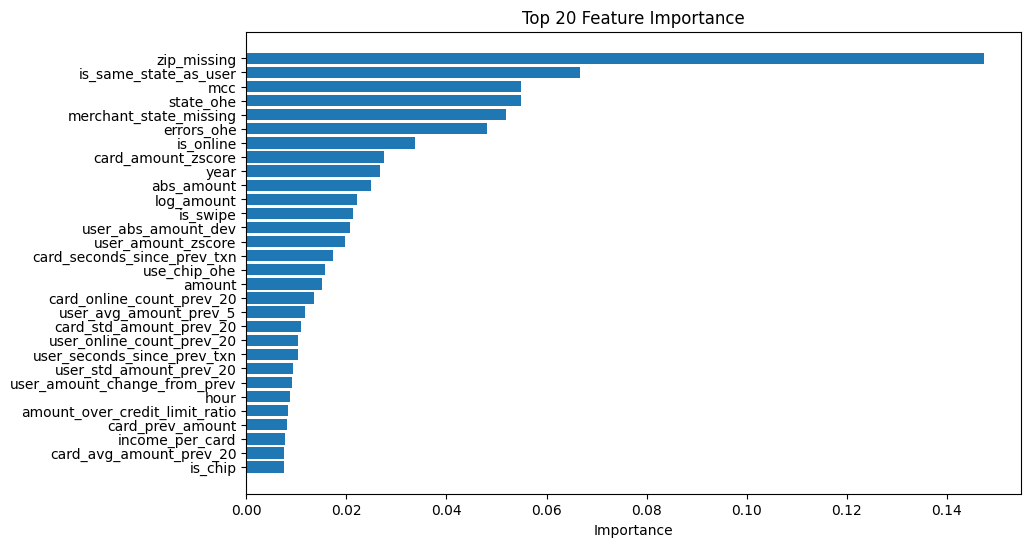

In [18]:
import matplotlib.pyplot as plt

top_rows = fi_spark_df.limit(30).collect()

features = [r["feature"] for r in top_rows]
importances = [r["importance"] for r in top_rows]

plt.figure(figsize=(10, 6))
plt.barh(features[::-1], importances[::-1])
plt.xlabel("Importance")
plt.title("Top 20 Feature Importance")
plt.show()